# From Orientation to Finals: Can a Start-of-Term Survey Predict Student Depression?

## 1. Frame the Problem and Look at the Big Picture

### Motivation

Depression is common among university students and often worsens over the course of a term as
academic pressure builds. Many struggling students do not seek help on their own, and
universities usually learn about them only after warning signs appear: missed classes, falling
grades, or a crisis.

Identifying students who may experience elevated depressive symptoms later in the term could help
universities offer support before symptoms escalate. Start-of-term depression, loneliness, and
flourishing surveys are short, inexpensive, and already validated, and may provide useful
information about students' subsequent mental health.

Beyond the institutional benefit, this is a public interest goal, since earlier support can reduce
suffering, protect academic progress, and make better use of counselling services that are often
over capacity.

### Objective

Evaluate whether start-of-term survey scores can predict students' end-of-term depressive
symptoms, framed as two supervised learning tasks:

1. **Regression (primary):** predict the end-of-term PHQ-9 score (0–27).
2. **Classification (secondary):** predict whether a student will be **at risk** at the end of
   term, defined as PHQ-9 ≥ 10, the established clinical cutoff for moderate depression
   (Kroenke et al., 2001).

We treat regression as the primary task because, with only 7 at-risk students, a binary label
throws away most of the information in the data: the full score distinguishes a student moving
from 2 to 8 from one staying at 2, and a good score model can always be thresholded at 10 to
produce the at-risk flag. The classification task is reported alongside it because it mirrors
the real decision: whom to contact.

We compare three nested sets of start-of-term predictors: baseline depression alone (A), plus
loneliness and flourishing (B), and plus perceived stress and neuroticism (C), and benchmark
them against a simple screening rule (flag students with PHQ-9 ≥ 10 at the start of term).

### Research question

Do start-of-term loneliness and flourishing scores, and additionally perceived stress and
neuroticism, improve prediction of (a) end-of-term depressive symptom severity and (b)
clinically significant symptoms (PHQ-9 ≥ 10), beyond start-of-term depression scores alone?

### Business value

Universities typically identify struggling students reactively, after grades drop or a crisis
occurs. A short survey at the start of term could flag students likely to experience
significant depressive symptoms, so counselling services can reach out early.

The **at-risk classifier** maps directly onto this decision: who should receive proactive
outreach? The **score model** gives a finer view of expected severity that could help prioritize
limited counselling capacity. Because missing a struggling student is costlier than an extra
check-in, we prioritize **recall** for the at-risk class.

The study also informs **survey design**: if extra questionnaires (loneliness, flourishing,
stress, neuroticism) do not improve prediction beyond a depression survey alone, universities can
keep the screening short, which matters for response rates. Given the small sample (38 students),
results should be treated as a pilot and validated at larger scale before any real deployment.

### Who uses the solution and how

**Primary users:** university counselling and student wellness services.

**Workflow:**
1. At the start of term, students voluntarily complete a short survey (PHQ-9 plus the additional
   questionnaires the final model needs), for example during orientation or in a first-week check-in.
2. The model scores each student once and flags those predicted to be at risk of clinically
   significant symptoms by the end of term.
3. Wellness staff reach out to flagged students with low-intensity support (a check-in, workshop
   invitation, or information about counselling) before the busy mid-term period.

**Important boundaries:** the model is a **screening aid, not a diagnosis**. It only prioritizes
outreach; all decisions stay with trained staff. Any student who reports thoughts of self-harm
(PHQ-9 item 9) should be followed up immediately, regardless of the model's prediction.
Participation must be voluntary, with informed consent and confidential handling of responses.

### Current solutions and workarounds

- **Self-referral:** students contact counselling services themselves. This misses students who
  do not recognize their symptoms or avoid seeking help.
- **Reactive identification:** professors, advisors, or residence staff notice warning signs
  (absences, falling grades), usually after symptoms are already severe.
- **One-off screening with a fixed cutoff:** some institutions screen with the PHQ-9 and flag
  scores ≥ 10. This only captures students who are *already* symptomatic and misses those who
  will get worse.

Our baseline reproduces the third approach. In the training data, the simple rule
"flag PHQ-9 ≥ 10 at start of term" missed 2 of 6 at-risk students, both of whom worsened during
the term. Our model is useful only if it improves on this rule.

### Framing the problem

| Decision | Choice | Justification |
|---|---|---|
| Learning type | **Supervised** | We observe the true end-of-term PHQ-9 score for every student, so we can learn a mapping from start-of-term surveys to a known outcome. |
| Task type | **Regression** (primary) and **binary classification** (secondary) | The score preserves full information about severity; the at-risk label (PHQ-9 ≥ 10) matches the real decision of whom to contact. |
| Training mode | **Offline (batch) learning** | Data arrives once per term, in a single survey wave; there is no continuous data stream to justify online learning. The model would be retrained each year as new survey data is collected. |
| Prediction mode | **Batch prediction** | All students are scored once at the start of term, not in real time. |
| Unit of analysis | One row per student | Each student's start-of-term scores (X) are paired with their own end-of-term outcome (y). |

In [1]:
import sys

assert sys.version_info >= (3, 7)

In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

## 2. Data Acquisition

We are using the StudentLife dataset, accessed through Kaggle. The data originated from a Dartmouth College study conducted during the spring term of 2013, following 48 students over 10 weeks. The study examined students’ mental health, academic performance, and behavioral patterns using smartphone sensing and surveys.

Students completed mental health questionnaires at the beginning and end of the study. This longitudinal structure allows us to investigate whether information collected at the start of term can predict depressive symptoms at the end. Our project focuses on three core survey files from the same study, plus two additional surveys (Perceived Stress and Big Five personality) tested as extra predictors.

In [3]:
%pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

def load_studentlife_data(file_name):
    return kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        "dartweichen/student-life",
        f"dataset/survey/{file_name}"
    )

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### **Selected Survey Files**

1. PHQ-9.csv — Depressive Symptoms

The **Patient Health Questionnaire-9 (PHQ-9)** measures depressive symptom severity through nine items. Using standard scoring, the total ranges from **0 to 27**, with higher scores indicating greater symptom severity.

**How we will use it:**

- **Pre-survey PHQ-9 score:** Predictor representing baseline depressive symptoms.
- **Post-survey PHQ-9 score:** Target. Used directly as the regression target (0–27), and
  converted into a binary **at-risk** label (PHQ-9 ≥ 10) for the classification task.

**Why we selected it:**  
   Baseline depression provides a benchmark for predicting later symptoms. Including it allows us to assess whether the other questionnaires (loneliness, flourishing, stress, neuroticism) improve prediction beyond what is already explained by initial depression scores.

In [4]:
phq9_df = load_studentlife_data("PHQ-9.csv")
phq9_df.head()

,uid,type,Little interest or pleasure in doing things,"Feeling down, depressed, hopeless.","Trouble falling or staying asleep, or sleeping too much.",Feeling tired or having little energy,Poor appetite or overeating,Feeling bad about yourself or that you are a failure or have let yourself or your family down,"Trouble concentrating on things, such as reading the newspaper or watching television",Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,"Thoughts that you would be better off dead, or of hurting yourself",Response
0,u00,pre,Not at all,Several days,Not at all,Several days,Not at all,Not at all,Not at all,Not at all,Not at all,Not difficult at all
1,u01,pre,Several days,Several days,Several days,Several days,Not at all,Several days,Not at all,Not at all,Not at all,Very difficult
2,u02,pre,More than half the days,Several days,More than half the days,More than half the days,More than half the days,Several days,Several days,More than half the days,Not at all,Somewhat difficult
3,u03,pre,Not at all,Several days,Not at all,Not at all,Not at all,Not at all,Not at all,Several days,Not at all,Somewhat difficult
4,u04,pre,Several days,Several days,Not at all,Several days,Several days,Several days,Several days,Not at all,Not at all,Somewhat difficult


2. LonelinessScale.csv — Perceived Loneliness

The **UCLA Loneliness Scale** measures perceived loneliness and social isolation. Higher scores indicate greater loneliness after applying the published scoring method.

**How we will use it:**

- Use only the **pre-survey loneliness score** as a predictor.

**Why we selected it:**  
This measure allows us to test whether students’ perceived social disconnection adds predictive information about end-of-term depressive symptoms beyond baseline depression.

In [5]:
loneliness_df = load_studentlife_data("LonelinessScale.csv")
loneliness_df.head()

,uid,type,1. I feel in tune with the people around me,2. I lack companionship,3. There is no one I can turn to,4. I do not feel alone,5. I feel part of a group of friends,6. I have a lot in common with the people around me,7. I am no longer close to anyone,8. My interests and ideas are not shared by those around me,...,11. I feel left out,12. My social relationships are superficial,13. No one really knows me well,14. I feel isolated from others,15. I can find companionship when I want it,16. There are people who really understand me,17. I am unhappy being so withdrawn,18. People are around me but not with me,19. There are people I can talk to,20. There are people I can turn to
0,u00,pre,Sometimes,Rarely,Never,Never,Often,Sometimes,Never,Never,...,Rarely,Rarely,Never,Never,Often,Rarely,Often,Sometimes,Often,Often
1,u01,pre,Sometimes,Rarely,Rarely,Sometimes,Often,Often,Never,Never,...,Rarely,Rarely,Never,Rarely,Often,Often,Sometimes,Never,Often,Often
2,u02,pre,Sometimes,Rarely,Rarely,Often,Often,Often,Never,Often,...,Rarely,Never,Never,Never,Often,Often,Never,Never,Often,Often
3,u03,pre,Sometimes,Rarely,Never,Often,Rarely,Rarely,Sometimes,Sometimes,...,Rarely,Rarely,Sometimes,Sometimes,Sometimes,Often,Sometimes,Sometimes,Sometimes,Sometimes
4,u04,pre,Sometimes,Sometimes,Sometimes,Sometimes,Rarely,Sometimes,Never,Rarely,...,Sometimes,Sometimes,Sometimes,Sometimes,Rarely,Rarely,Sometimes,Sometimes,Rarely,Rarely


3. FlourishingScale.csv — Psychological Well-Being

The **Flourishing Scale** measures psychological well-being through eight items covering areas such as relationships, purpose, self-esteem, and optimism. Standard total scores range from **8 to 56**, with higher scores indicating greater flourishing.

**How we will use it:**

- Use only the **pre-survey flourishing score** as a predictor.

**Why we selected it:**  
Flourishing adds a positive well-being perspective, complementing the symptom-focused depression and loneliness measures. We will assess whether it improves prediction of end-of-term depressive symptoms.


In [6]:
flourishing_df = load_studentlife_data("FlourishingScale.csv")
flourishing_df.head()

,uid,type,I lead a purposeful and meaningful life,My social relationships are supportive and rewarding,I am engaged and interested in my daily activities,I actively contribute to the happiness and well-being of others,I am competent and capable in the activities that are important to me,I am a good person and live a good life,I am optimistic about my future,People respect me
0,u00,pre,7,6,NaN,6.0,6.0,7.0,7,4
1,u01,pre,4,6,6.0,6.0,7.0,6.0,4,6
2,u02,pre,6,7,5.0,6.0,5.0,6.0,4,7
3,u03,pre,6,2,2.0,4.0,5.0,6.0,5,4
4,u04,pre,3,5,4.0,3.0,2.0,2.0,3,5


### Data Exploration and Cleaning

1. PHQ-9.csv — Depressive Symptoms

In [7]:
print(phq9_df.shape)
phq9_df.info()

(84, 12)
<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 12 columns):
 #   Column                                                                                                                                                                 Non-Null Count  Dtype
---  ------                                                                                                                                                                 --------------  -----
 0   uid                                                                                                                                                                    84 non-null     str  
 1   type                                                                                                                                                                   84 non-null     str  
 2   Little interest or pleasure in doing things                                                                           

In [8]:
# Missing values by column
missing_summary = pd.DataFrame({
    "MissingCount": phq9_df.isna().sum(),
    "MissingPercent": phq9_df.isna().mean() * 100
})

display(missing_summary)

# Exact duplicate rows
print("Duplicate rows:", phq9_df.duplicated().sum())

,MissingCount,MissingPercent
uid,0,0.000000
type,0,0.000000
Little interest or pleasure in doing things,0,0.000000
"Feeling down, depressed, hopeless.",0,0.000000
"Trouble falling or staying asleep, or sleeping too much.",0,0.000000
Feeling tired or having little energy,0,0.000000
Poor appetite or overeating,0,0.000000
Feeling bad about yourself or that you are a failure or have let yourself or your family down,0,0.000000
"Trouble concentrating on things, such as reading the newspaper or watching television",0,0.000000
Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,0,0.000000


Duplicate rows: 0


In [9]:
phq9_df['type'].value_counts()

type
pre     46
post    38
Name: count, dtype: int64

In [10]:
# Check duplicate student + survey period combinations
print(
    "Duplicate student-period combinations:",
    phq9_df.duplicated(subset=["uid", "type"]).sum()
)

Duplicate student-period combinations: 0


In [11]:
# Count unique students and students with both survey periods
print("Unique students:", phq9_df["uid"].nunique())

survey_counts = pd.crosstab(phq9_df["uid"], phq9_df["type"])
print(
    "Students with both pre and post:",
    ((survey_counts["pre"] > 0) & (survey_counts["post"] > 0)).sum()
)

Unique students: 46
Students with both pre and post: 38


In [12]:
# Inspect answer categories across the nine symptom items
item_columns = phq9_df.columns[2:11]

display(
    phq9_df[item_columns]
    .melt(value_name="Answer")["Answer"]
    .value_counts(dropna=False)
)

Answer
Not at all                 412
Several days               234
More than half the days     72
Nearly every day            38
Name: count, dtype: int64

In [13]:
# Inspect the additional Response column
display(phq9_df["Response"].value_counts(dropna=False))

Response
Somewhat difficult      37
Not difficult at all    36
NaN                      5
Very difficult           3
Extremely difficult      3
Name: count, dtype: int64

**Findings and Data Cleaning Plan**

- The dataset contains 84 survey responses from 46 students: 46 pre-surveys and 38 post-surveys. We will retain the 38 students who completed both surveys for modeling because we need each student’s baseline predictors and observed end-of-term outcome to train and evaluate the model.
- We will match pre- and post-survey responses using `uid`. The 8 students without post-survey outcomes will be excluded from modeling; their missing outcomes will not be imputed.
- All nine symptom questions are complete. The additional `Response` column has 5 missing values (5.95%), but it is excluded from the PHQ-9 total, so these missing values will not cause any rows to be dropped.
- We will encode the nine symptom responses from 0 to 3 and sum them to calculate the standard PHQ-9 total (0–27).
- Pre-survey scores will serve as predictors, and post-survey PHQ-9 scores will serve as the outcome.

In [14]:
# Create a working copy of the raw PHQ-9 data and standardize IDs and survey labels
# (same cleaning applied to the loneliness and flourishing tables)
phq9_clean = phq9_df.copy()

phq9_clean["uid"] = phq9_clean["uid"].str.strip()
phq9_clean["type"] = phq9_clean["type"].str.strip().str.lower()

In [15]:
from sklearn.preprocessing import OrdinalEncoder

# Select the nine symptom questions
item_columns = phq9_df.columns[2:11]

# Define the scoring order: 0, 1, 2, 3
response_order = [
    "Not at all",
    "Several days",
    "More than half the days",
    "Nearly every day"
]

encoder = OrdinalEncoder(
    categories=[response_order for _ in item_columns],
    dtype=int
)

# Encode the nine symptom questions
phq9_clean[item_columns] = encoder.fit_transform(
    phq9_df[item_columns].apply(lambda column: column.str.strip())
)

# Calculate the total score
phq9_clean["phq9_total"] = phq9_clean[item_columns].sum(
    axis=1, min_count=9
)

phq9_clean.head()

,uid,type,Little interest or pleasure in doing things,"Feeling down, depressed, hopeless.","Trouble falling or staying asleep, or sleeping too much.",Feeling tired or having little energy,Poor appetite or overeating,Feeling bad about yourself or that you are a failure or have let yourself or your family down,"Trouble concentrating on things, such as reading the newspaper or watching television",Moving or speaking so slowly that other people could have noticed. Or the opposite being so figety or restless that you have been moving around a lot more than usual,"Thoughts that you would be better off dead, or of hurting yourself",Response,phq9_total
0,u00,pre,0,1,0,1,0,0,0,0,0,Not difficult at all,2
1,u01,pre,1,1,1,1,0,1,0,0,0,Very difficult,5
2,u02,pre,2,1,2,2,2,1,1,2,0,Somewhat difficult,13
3,u03,pre,0,1,0,0,0,0,0,1,0,Somewhat difficult,2
4,u04,pre,1,1,0,1,1,1,1,0,0,Somewhat difficult,6


In [16]:
# Create one row per student with separate pre and post scores
phq9_paired = (
    phq9_clean.pivot(
        index="uid",
        columns="type",
        values="phq9_total"
    )
    .rename(columns={
        "pre": "phq9_pre",
        "post": "phq9_post"
    })
    .rename_axis(columns=None)
    .reset_index()
)

# Exclude students without both scores
phq9_paired = phq9_paired.dropna(
    subset=["phq9_pre", "phq9_post"]
).reset_index(drop=True)

# Verify the result
print("Students retained:", len(phq9_paired))
display(phq9_paired.head())

Students retained: 38


,uid,phq9_post,phq9_pre
0,u00,3.0,2.0
1,u01,4.0,5.0
2,u02,5.0,13.0
3,u03,4.0,2.0
4,u04,8.0,6.0


2. LonelinessScale.csv — Perceived Loneliness

In [17]:
print("Shape:", loneliness_df.shape)
loneliness_df.info()

Shape: (83, 22)
<class 'pandas.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 22 columns):
 #   Column                                                       Non-Null Count  Dtype
---  ------                                                       --------------  -----
 0   uid                                                          83 non-null     str  
 1   type                                                         83 non-null     str  
 2   1. I feel in tune with the people around me                  83 non-null     str  
 3   2. I lack companionship                                      83 non-null     str  
 4   3. There is no one I can turn to                             83 non-null     str  
 5   4. I do not feel alone                                       83 non-null     str  
 6   5. I feel part of a group of friends                         83 non-null     str  
 7   6. I have a lot in common with the people around me          83 non-null     str  
 8   7. I am

In [18]:
# Check survey periods
display(loneliness_df["type"].value_counts(dropna=False))

# Check duplicates
print("Duplicate rows:", loneliness_df.duplicated().sum())
print(
    "Duplicate student-period combinations:",
    loneliness_df.duplicated(subset=["uid", "type"]).sum()
)

type
pre     46
post    37
Name: count, dtype: int64

Duplicate rows: 0
Duplicate student-period combinations: 0


In [19]:
# Inspect response categories for each question
for column in loneliness_df.columns:
    if column not in ["uid", "type"]:
        print(f"\n{column}:")
        print(loneliness_df[column].value_counts(dropna=False).to_string())


1. I feel in tune with the people around me:
1. I feel in tune with the people around me
Sometimes    42
Often        31
Rarely       10

2. I lack companionship:
2. I lack companionship
Rarely       35
Sometimes    26
Never        14
Often         8

3. There is no one I can turn to:
3. There is no one I can turn to
Never        38
Rarely       24
Sometimes    16
Often         5

4. I do not feel alone:
4. I do not feel alone
Often        45
Sometimes    24
Rarely       10
Never         4

5. I feel part of a group of friends:
5. I feel part of a group of friends
Often        45
Sometimes    22
Rarely       12
Never         4

6. I have a lot in common with the people around me:
6. I have a lot in common with the people around me
Often        34
Sometimes    28
Rarely       17
Never         4

7. I am no longer close to anyone:
7. I am no longer close to anyone
Never        41
Rarely       20
Sometimes    15
Often         7

8. My interests and ideas are not shared by those around me

In [20]:
# Preserve the original data
loneliness_clean = loneliness_df.copy()

# Standardize identifiers and survey labels
loneliness_clean["uid"] = loneliness_clean["uid"].str.strip()
loneliness_clean["type"] = (
    loneliness_clean["type"].str.strip().str.lower()
)

# Keep only baseline responses
loneliness_clean = loneliness_clean.loc[
    loneliness_clean["type"] == "pre"
].copy()

# Select the 20 survey questions
loneliness_items = [
    column for column in loneliness_clean.columns
    if column not in ["uid", "type"]
]

# Inspect all baseline answer categories
display(
    loneliness_clean[loneliness_items]
    .melt(value_name="Answer")["Answer"]
    .value_counts(dropna=False)
)

print("Baseline responses retained:", len(loneliness_clean))

Answer
Sometimes    290
Often        262
Rarely       216
Never        152
Name: count, dtype: int64

Baseline responses retained: 46


**Findings and Data Cleaning Plan**

- The dataset contains 83 survey responses: 46 pre-surveys and 37 post-surveys, with 20 questionnaire items.
- No missing values, duplicate rows, or duplicate student–survey period combinations were found.
- We will retain only the 46 pre-survey responses, because baseline loneliness will be used to predict end-of-term PHQ-9 scores. Post-survey loneliness responses are not required.
- We will remove extra spaces from student IDs and response labels to ensure consistent encoding and matching.
- We will encode responses in their ordered categories and reverse-score the appropriate items so that higher scores consistently indicate greater loneliness.
- We will calculate the total loneliness score using all 20 correctly scored items and check for missing scores and values outside the expected range.
- We will retain `uid` and `loneliness_pre` for merging with the PHQ-9 table. Only students with the required observed PHQ-9 outcome will enter supervised modeling.

In [21]:
# Create a copy and standardize IDs and survey labels
loneliness_clean = loneliness_df.copy()

loneliness_clean["uid"] = loneliness_clean["uid"].str.strip()
loneliness_clean["type"] = (
    loneliness_clean["type"].str.strip().str.lower()
)

In [22]:
# keep only pre survey response
loneliness_clean = loneliness_clean.loc[
    loneliness_clean["type"] == "pre"
].copy()

print("Baseline students retained:", len(loneliness_clean))

Baseline students retained: 46


In [23]:
# Select the 20 questions and clean response labels
loneliness_items = [
    column for column in loneliness_clean.columns
    if column not in ["uid", "type"]
]

loneliness_clean[loneliness_items] = (
    loneliness_clean[loneliness_items]
    .apply(lambda column: column.str.strip())
)

In [24]:
# Check for missing responses and duplicate students
assert len(loneliness_items) == 20, "Expected 20 questions."

assert loneliness_clean["uid"].notna().all(), \
    "Missing student IDs."

assert not loneliness_clean["uid"].duplicated().any(), \
    "Duplicate baseline responses."

assert loneliness_clean[loneliness_items].notna().all().all(), \
    "Missing questionnaire responses."

In [25]:
# Encode responses from 1 to 4
from sklearn.preprocessing import OrdinalEncoder

response_order = ["Never", "Rarely", "Sometimes", "Often"]

loneliness_encoder = OrdinalEncoder(
    categories=[response_order for _ in loneliness_items],
    dtype=int
)

loneliness_clean[loneliness_items] = (
    loneliness_encoder.fit_transform(
        loneliness_clean[loneliness_items]
    ) + 1
)

In [26]:
# Reverse-score the positively worded questions
reverse_numbers = {1, 4, 5, 6, 9, 10, 15, 16, 19, 20}

reverse_columns = [
    column for column in loneliness_items
    if int(column.split(".")[0].strip()) in reverse_numbers
]

assert len(reverse_columns) == 10, \
    "Check reverse-scored column names."

loneliness_clean[reverse_columns] = (
    5 - loneliness_clean[reverse_columns]
)

In [27]:
loneliness_clean.head()

,uid,type,1. I feel in tune with the people around me,2. I lack companionship,3. There is no one I can turn to,4. I do not feel alone,5. I feel part of a group of friends,6. I have a lot in common with the people around me,7. I am no longer close to anyone,8. My interests and ideas are not shared by those around me,...,11. I feel left out,12. My social relationships are superficial,13. No one really knows me well,14. I feel isolated from others,15. I can find companionship when I want it,16. There are people who really understand me,17. I am unhappy being so withdrawn,18. People are around me but not with me,19. There are people I can talk to,20. There are people I can turn to
0,u00,pre,2,2,1,4,1,2,1,1,...,2,2,1,1,1,3,4,3,1,1
1,u01,pre,2,2,2,2,1,1,1,1,...,2,2,1,2,1,1,3,1,1,1
2,u02,pre,2,2,2,1,1,1,1,4,...,2,1,1,1,1,1,1,1,1,1
3,u03,pre,2,2,1,1,3,3,3,3,...,2,2,3,3,2,1,3,3,2,2
4,u04,pre,2,3,3,2,3,2,1,2,...,3,3,3,3,3,3,3,3,3,3


In [28]:
# calculate and validate total score
loneliness_clean["loneliness_pre"] = (
    loneliness_clean[loneliness_items].sum(axis=1, min_count=20)
)

assert loneliness_clean["loneliness_pre"].between(20, 80).all(), \
    "Missing or out-of-range totals found."

In [29]:
# prepare the table for merging
loneliness_pre = loneliness_clean[
    ["uid", "loneliness_pre"]
].reset_index(drop=True)

display(loneliness_pre.head())

,uid,loneliness_pre
0,u00,35
1,u01,30
2,u02,29
3,u03,47
4,u04,53


3. FlourishingScale.csv — Psychological Well-Being

In [30]:
print("Shape:", flourishing_df.shape)
flourishing_df.info()

Shape: (83, 10)
<class 'pandas.DataFrame'>
RangeIndex: 83 entries, 0 to 82
Data columns (total 10 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   uid                                                                    83 non-null     str    
 1   type                                                                   83 non-null     str    
 2   I lead a purposeful and meaningful life                                83 non-null     int64  
 3   My social relationships are supportive and rewarding                   83 non-null     int64  
 4   I am engaged and interested in my daily activities                     80 non-null     float64
 5   I actively contribute to the happiness and well-being of others        82 non-null     float64
 6   I am competent and capable in the activities that are important to me  82 non-null     

In [31]:
display(flourishing_df["type"].value_counts(dropna=False))

print("Duplicate rows:", flourishing_df.duplicated().sum())

print(
    "Duplicate student-period combinations:",
    flourishing_df.duplicated(subset=["uid", "type"]).sum()
)

type
pre     46
post    37
Name: count, dtype: int64

Duplicate rows: 0
Duplicate student-period combinations: 0


In [32]:
for column in flourishing_df.columns:
    if column not in ["uid", "type"]:
        print(f"\n{column}:")
        print(
            flourishing_df[column]
            .value_counts(dropna=False)
            .to_string()
        )


I lead a purposeful and meaningful life:
I lead a purposeful and meaningful life
6    29
7    23
5    18
3     6
4     4
2     2
1     1

My social relationships are supportive and rewarding:
My social relationships are supportive and rewarding
6    32
5    18
7    16
2     6
4     6
3     3
1     2

I am engaged and interested in my daily activities:
I am engaged and interested in my daily activities
6.0    24
5.0    19
4.0    15
7.0    11
2.0     7
3.0     4
NaN     3

I actively contribute to the happiness and well-being of others:
I actively contribute to the happiness and well-being of others
6.0    34
5.0    22
4.0     8
3.0     8
7.0     5
1.0     3
2.0     2
NaN     1

I am competent and capable in the activities that are important to me:
I am competent and capable in the activities that are important to me
6.0    29
7.0    18
5.0    18
4.0    10
2.0     4
3.0     3
NaN     1

I am a good person and live a good life:
I am a good person and live a good life
7.0    32
6.0    27


The flourishing survey has 83 responses: 46 pre and 37 post, with no duplicates. Its eight questionnaire items are already numeric, so no encoder is needed.

There are 6 missing responses across four questions, but we first need to check whether they occur in the pre-surveys we will use.

In [33]:
# Create a copy and standardize IDs and labels
flourishing_clean = flourishing_df.copy()

flourishing_clean["uid"] = flourishing_clean["uid"].str.strip()
flourishing_clean["type"] = (
    flourishing_clean["type"].str.strip().str.lower()
)

In [34]:
# Keep only pre-survey responses
flourishing_clean = flourishing_clean.loc[
    flourishing_clean["type"] == "pre"
].copy()

print("Baseline students retained:", len(flourishing_clean))

Baseline students retained: 46


In [35]:
# Select the eight questions and check baseline missingness
flourishing_items = [
    column for column in flourishing_clean.columns
    if column not in ["uid", "type"]
]

display(flourishing_clean[flourishing_items].isna().sum())

print(
    "Students with at least one missing item:",
    flourishing_clean[flourishing_items].isna().any(axis=1).sum()
)

I lead a purposeful and meaningful life                                  0
My social relationships are supportive and rewarding                     0
I am engaged and interested in my daily activities                       3
I actively contribute to the happiness and well-being of others          1
I am competent and capable in the activities that are important to me    1
I am a good person and live a good life                                  1
I am optimistic about my future                                          0
People respect me                                                        0
dtype: int64

Students with at least one missing item: 4


In [36]:
# Inspect the numeric response values
display(
    flourishing_clean[flourishing_items]
    .melt(value_name="Score")["Score"]
    .value_counts(dropna=False)
    .sort_index()
)

Score
1.0      6
2.0     17
3.0     17
4.0     42
5.0     76
6.0    129
7.0     75
NaN      6
Name: count, dtype: int64

The baseline flourishing data shows:
- 6 missing item responses across 4 students.
- 42 students have complete responses.
- All observed item values are between 1 and 7.
For now, we are keeping all 46 students and leaving incomplete totals missing. After merging, we can see how many of those four students have PHQ-9 outcomes before deciding how to handle missing predictors.

In [37]:
# Validate the observed item values
assert len(flourishing_items) == 8, "Expected eight questions."

assert (
    flourishing_clean[flourishing_items].isin(range(1, 8))
    | flourishing_clean[flourishing_items].isna()
).all().all(), "Unexpected item values found."

In [38]:
# Calculate totals only for complete surveys
flourishing_clean["flourishing_pre"] = (
    flourishing_clean[flourishing_items].sum(axis=1, min_count=8)
)

In [39]:
# Prepare the table for merging
flourishing_pre = flourishing_clean[
    ["uid", "flourishing_pre"]
].reset_index(drop=True)

print("Students retained:", len(flourishing_pre))
print("Missing totals:", flourishing_pre["flourishing_pre"].isna().sum())

display(flourishing_pre.head())

Students retained: 46
Missing totals: 4


,uid,flourishing_pre
0,u00,NaN
1,u01,45.0
2,u02,46.0
3,u03,34.0
4,u04,27.0


#### Extending the Predictor Set: Stress and Neuroticism

Our original proposal used three start-of-term predictors (PHQ-9, loneliness, flourishing).
Because the sample is small, we reviewed the other StudentLife surveys for measures with strong
theoretical links to depression and added two:

- **Perceived stress (PSS-10):** stress is a well-established trigger for depressive symptoms.
- **Neuroticism (Big Five):** a stable personality trait associated with vulnerability to
  depression.

With only 30 training students, every extra predictor increases the risk of overfitting, and both new measures are likely correlated with the existing predictors. Rather than assuming they help, we treat them as an experiment and compare three nested feature sets with cross-validation:

| Model | Predictors |
|---|---|
| A | PHQ-9 pre only (baseline) |
| B | + loneliness, flourishing (original proposal) |
| C | + perceived stress, neuroticism (extended) |

If Model C does not improve cross-validated performance over Model B, we keep the simpler model
and report this as a finding.

4. PerceivedStressScale.csv — Perceived Stress

The **Perceived Stress Scale (PSS-10)** measures how unpredictable, uncontrollable, and
overloaded students find their lives. Each item is scored 0–4; four positively worded items
(4, 5, 7, 8) are reverse-scored, giving a total of **0–40** (higher = more stress).

**Why we added it:** stress is a well-established risk factor for depression. Because our sample
is small, we add it as an *extra* predictor and test with cross-validation whether it improves on
the original three-predictor model, rather than assuming it helps.

In [40]:
# Load and clean the Perceived Stress Scale (PSS-10), keeping only start-of-term responses
stress_df = load_studentlife_data("PerceivedStressScale.csv")

stress_clean = stress_df.copy()
stress_clean["uid"] = stress_clean["uid"].str.strip()
stress_clean["type"] = stress_clean["type"].str.strip().str.lower()
stress_clean = stress_clean.loc[stress_clean["type"] == "pre"].copy()

stress_items = [column for column in stress_clean.columns if column not in ["uid", "type"]]
assert len(stress_items) == 10, "Expected 10 questions."

# Inspect answer categories and missing items before encoding
display(
    stress_clean[stress_items].melt(value_name="Answer")["Answer"]
    .value_counts(dropna=False)
)
print("Baseline students:", len(stress_clean))
print("Students with a missing item:",
      stress_clean.loc[stress_clean[stress_items].isna().any(axis=1), "uid"].tolist())

Answer
Sometime        165
Almost never    115
Fairly often    109
Very often       46
Never            23
NaN               2
Name: count, dtype: int64

Baseline students: 46
Students with a missing item: ['u31', 'u45']


In [41]:
# Encode 0–4, reverse-score the positively worded items (4, 5, 7, 8), and total (0–40)
stress_scores = {"Never": 0, "Almost never": 1, "Sometime": 2, "Fairly often": 3, "Very often": 4}

stress_clean[stress_items] = stress_clean[stress_items].apply(
    lambda column: column.str.strip().map(stress_scores)
)

reverse_stress = [
    column for column in stress_items
    if int(column.split(".")[0]) in {4, 5, 7, 8}
]
assert len(reverse_stress) == 4, "Check reverse-scored column names."
stress_clean[reverse_stress] = 4 - stress_clean[reverse_stress]

# Total only for complete surveys; incomplete totals stay missing and are imputed in the pipeline
stress_clean["stress_pre"] = stress_clean[stress_items].sum(axis=1, min_count=10)
assert stress_clean["stress_pre"].dropna().between(0, 40).all()

stress_pre = stress_clean[["uid", "stress_pre"]].reset_index(drop=True)
print("Missing totals:", stress_pre["stress_pre"].isna().sum())
display(stress_pre.head())

Missing totals: 2


,uid,stress_pre
0,u00,24.0
1,u01,15.0
2,u02,21.0
3,u03,17.0
4,u04,21.0


5. BigFive.csv — Neuroticism

The Big Five Inventory (BFI-44) measures five personality traits. We use only the
**Neuroticism** subscale: 8 items (4, 9, 14, 19, 24, 29, 34, 39) describing a tendency toward
worry, tension, and negative emotion. Items are scored 1–5, with three reverse-scored items
(9, 24, 34), giving a total of **8–40** (higher = more neurotic).

**Why we added it:** neuroticism is a stable trait strongly linked to vulnerability to
depression. Note that one item ("Is depressed, blue") overlaps conceptually with the PHQ-9, so
some of neuroticism's predictive power may duplicate baseline depression.

In [42]:
# Load the Big Five Inventory (BFI-44) and keep only start-of-term responses
bigfive_df = load_studentlife_data("BigFive.csv")

bigfive_clean = bigfive_df.copy()
bigfive_clean["uid"] = bigfive_clean["uid"].str.strip()
bigfive_clean["type"] = bigfive_clean["type"].str.strip().str.lower()
bigfive_clean = bigfive_clean.loc[bigfive_clean["type"] == "pre"].copy()

# Item number is the text between "- " and the first "." in each column name
def bfi_item_number(column):
    return int(column.split("- ")[1].split(".")[0])

# Neuroticism subscale = items 4, 9, 14, 19, 24, 29, 34, 39 (John & Srivastava, 1999)
neuroticism_numbers = {4, 9, 14, 19, 24, 29, 34, 39}
neuroticism_items = [
    column for column in bigfive_clean.columns
    if column not in ["uid", "type"] and bfi_item_number(column) in neuroticism_numbers
]
assert len(neuroticism_items) == 8, "Expected 8 Neuroticism items."

for column in neuroticism_items:
    print(column.split("- ")[1])
print("\nBaseline students:", len(bigfive_clean))
print("Students with a missing Neuroticism item:",
      bigfive_clean.loc[bigfive_clean[neuroticism_items].isna().any(axis=1), "uid"].tolist())

4. Is depressed, blue
9. Is relaxed, handles stress well.
14. Can be tense
19. Worries a lot
24. Is emotionally stable, not easily upset
29. Can be moody
34. Remains calm in tense situations
39. Gets nervous easily

Baseline students: 46
Students with a missing Neuroticism item: ['u07', 'u14']


In [43]:
# Encode 1–5 (case-insensitive), reverse-score items 9, 24, 34, and total (8–40)
bfi_scores = {
    "disagree strongly": 1,
    "disagree a little": 2,
    "neither agree nor disagree": 3,
    "agree a little": 4,
    "agree strongly": 5,
}

bigfive_clean[neuroticism_items] = bigfive_clean[neuroticism_items].apply(
    lambda column: column.str.strip().str.lower().map(bfi_scores)
)

reverse_neuroticism = [c for c in neuroticism_items if bfi_item_number(c) in {9, 24, 34}]
assert len(reverse_neuroticism) == 3, "Check reverse-scored column names."
bigfive_clean[reverse_neuroticism] = 6 - bigfive_clean[reverse_neuroticism]

bigfive_clean["neuroticism_pre"] = bigfive_clean[neuroticism_items].sum(axis=1, min_count=8)
assert bigfive_clean["neuroticism_pre"].dropna().between(8, 40).all()

neuroticism_pre = bigfive_clean[["uid", "neuroticism_pre"]].reset_index(drop=True)
print("Missing totals:", neuroticism_pre["neuroticism_pre"].isna().sum())
display(neuroticism_pre.head())

Missing totals: 2


,uid,neuroticism_pre
0,u00,25.0
1,u01,22.0
2,u02,28.0
3,u03,27.0
4,u04,33.0


### Dataset for the Model

In [44]:
# Add baseline loneliness to the paired PHQ-9 table
student_data = phq9_paired.merge(
    loneliness_pre, 
    on="uid", 
    how="left", 
    validate="one_to_one"
)
# Add baseline flourishing
student_data = student_data.merge(
    flourishing_pre,
    on="uid",
    how="left",
    validate="one_to_one"
)
# Add baseline perceived stress and neuroticism (extra predictors)
student_data = student_data.merge(
    stress_pre,
    on="uid",
    how="left",
    validate="one_to_one"
)
student_data = student_data.merge(
    neuroticism_pre,
    on="uid",
    how="left",
    validate="one_to_one"
)
student_data.head()

,uid,phq9_post,phq9_pre,loneliness_pre,flourishing_pre,stress_pre,neuroticism_pre
0,u00,3.0,2.0,35,NaN,24.0,25.0
1,u01,4.0,5.0,30,45.0,15.0,22.0
2,u02,5.0,13.0,29,46.0,21.0,28.0
3,u03,4.0,2.0,47,34.0,17.0,27.0
4,u04,8.0,6.0,53,27.0,21.0,33.0


In [45]:
print("Shape:", student_data.shape)
print("Unique students:", student_data["uid"].nunique())

display(student_data.isna().sum())

assert student_data["uid"].is_unique
assert student_data["phq9_post"].notna().all()

Shape: (38, 7)
Unique students: 38


uid                0
phq9_post          0
phq9_pre           0
loneliness_pre     0
flourishing_pre    3
stress_pre         2
neuroticism_pre    2
dtype: int64

### Test-Train Split

In [46]:
from sklearn.model_selection import train_test_split

# Secondary outcome: clinically significant depressive symptoms at end of term
# PHQ-9 >= 10 is the established cutoff for moderate depression (Kroenke et al., 2001)
student_data["at_risk"] = (student_data["phq9_post"] >= 10).astype(int)

print("At-risk students in full dataset:")
print(student_data["at_risk"].value_counts().to_string())

# Stratify on the at-risk flag so the rare positive class appears in both sets
train_data, test_data = train_test_split(
    student_data,
    test_size=0.20,
    random_state=42,
    stratify=student_data["at_risk"]
)

print("\nTraining students:", len(train_data), "| at risk:", train_data["at_risk"].sum())
print("Test students:", len(test_data), "| at risk:", test_data["at_risk"].sum())

At-risk students in full dataset:
at_risk
0    31
1     7

Training students: 30 | at risk: 6
Test students: 8 | at risk: 1


We hold out 20% of students as a test set before any exploration, so that EDA and preprocessing
decisions are based on training data only (avoiding data leakage). Because only 7 of 38 students
reach the clinical cutoff (PHQ-9 ≥ 10), we stratify the split on this at-risk flag so both sets
contain positive cases. Even so, the test set contains only 1 at-risk student, so test-set
classification metrics will be unstable; model comparison for the at-risk outcome will rely
primarily on cross-validation within the training set.

## 3. Explore the Data (Training Data Only)

In [47]:
student_train = train_data.copy()

In [48]:
# Profile each attribute: role, valid range, missingness, and distribution shape
features = ["phq9_pre", "loneliness_pre", "flourishing_pre", "stress_pre", "neuroticism_pre"]
target = "phq9_post"

scale_ranges = {
    "phq9_pre": (0, 27),
    "loneliness_pre": (20, 80),
    "flourishing_pre": (8, 56),
    "stress_pre": (0, 40),
    "neuroticism_pre": (8, 40),
    "phq9_post": (0, 27),
}

profile_rows = []
for column in features + [target]:
    values = student_train[column]
    profile_rows.append({
        "attribute": column,
        "role": "target" if column == target else "predictor",
        "type": "integer score (bounded)",
        "valid_range": f"{scale_ranges[column][0]}–{scale_ranges[column][1]}",
        "pct_missing": round(values.isna().mean() * 100, 1),
        "min": values.min(),
        "median": values.median(),
        "max": values.max(),
        "mean": round(values.mean(), 1),
        "std": round(values.std(), 1),
        "skew": round(values.skew(), 2),
    })

attribute_profile = pd.DataFrame(profile_rows).set_index("attribute")
display(attribute_profile)

# Flag potential outliers with the 1.5 × IQR rule
for column in features + [target]:
    values = student_train[column]
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = student_train.loc[
        (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr),
        ["uid", column]
    ]
    print(f"{column}: {len(outliers)} potential outlier(s)",
          outliers.values.tolist())

,role,type,valid_range,pct_missing,min,median,max,mean,std,skew
attribute,,,,,,,,,,
phq9_pre,predictor,integer score (bounded),0–27,0.0,0.0,5.0,23.0,5.9,5.2,1.51
loneliness_pre,predictor,integer score (bounded),20–80,0.0,22.0,35.0,65.0,39.3,13.2,0.58
flourishing_pre,predictor,integer score (bounded),8–56,10.0,16.0,45.0,54.0,42.7,8.8,-1.27
stress_pre,predictor,integer score (bounded),0–40,6.7,3.0,19.0,33.0,18.3,6.5,-0.26
neuroticism_pre,predictor,integer score (bounded),8–40,3.3,14.0,25.0,36.0,24.9,5.8,0.04
phq9_post,target,integer score (bounded),0–27,0.0,0.0,4.5,25.0,6.4,6.0,1.58


phq9_pre: 1 potential outlier(s) [['u33', 23.0]]
loneliness_pre: 0 potential outlier(s) []
flourishing_pre: 1 potential outlier(s) [['u31', 16.0]]
stress_pre: 0 potential outlier(s) []
neuroticism_pre: 0 potential outlier(s) []
phq9_post: 2 potential outlier(s) [['u33', 25.0], ['u23', 21.0]]


**Attribute profile takeaways**

- **All attributes are bounded integer scores** from validated questionnaires, so values are
  constrained by design and every value falls within its valid range.
- **Missing data:** `flourishing_pre` (10%, 3 students), `stress_pre` (6.7%, 2 students) and
  `neuroticism_pre` (3.3%, 1 student) have missing totals, each caused by a single skipped item
  (three for one flourishing respondent). We impute these inside the modeling pipeline using the
  training median.
- **Skewness:** PHQ-9 scores are right-skewed (skew ≈ 1.5 pre and 1.6 post): most students report
  minimal symptoms and a few report severe ones. Flourishing is left-skewed (≈ −1.3). Loneliness
  (0.6), stress (−0.3) and neuroticism (0.0) are roughly symmetric. This suggests a log transform
  for PHQ-9 only.
- **Outliers:** the IQR rule flags u33 (PHQ-9 = 23 pre, 25 post), u23 (PHQ-9 post = 21), and u31
  (flourishing = 16); loneliness, stress and neuroticism have none. These are **real, clinically
  meaningful responses, not errors**, and they are exactly the students a screening tool should
  catch, so we keep them. With n = 30, they will strongly influence linear models, which we
  account for when choosing models.
- **Noise:** scores are self-reported, so the main noise is **measurement noise** (social
  desirability, mood on the day, interpreting "several days" vs "more than half the days"),
  not recording errors. Scores are whole numbers by design (no rounding noise). The only
  irregularities are a few skipped items (flourishing, stress, neuroticism) and the real extreme
  scores noted above.
- **Usefulness:** all five predictors are directly tied to the objective (start-of-term screening).
  `phq9_pre` is expected to be the strongest predictor, since it measures the same construct as the
  target. Loneliness and flourishing are the predictors from our original proposal; stress and
  neuroticism are extra predictors whose added value we test with cross-validation.

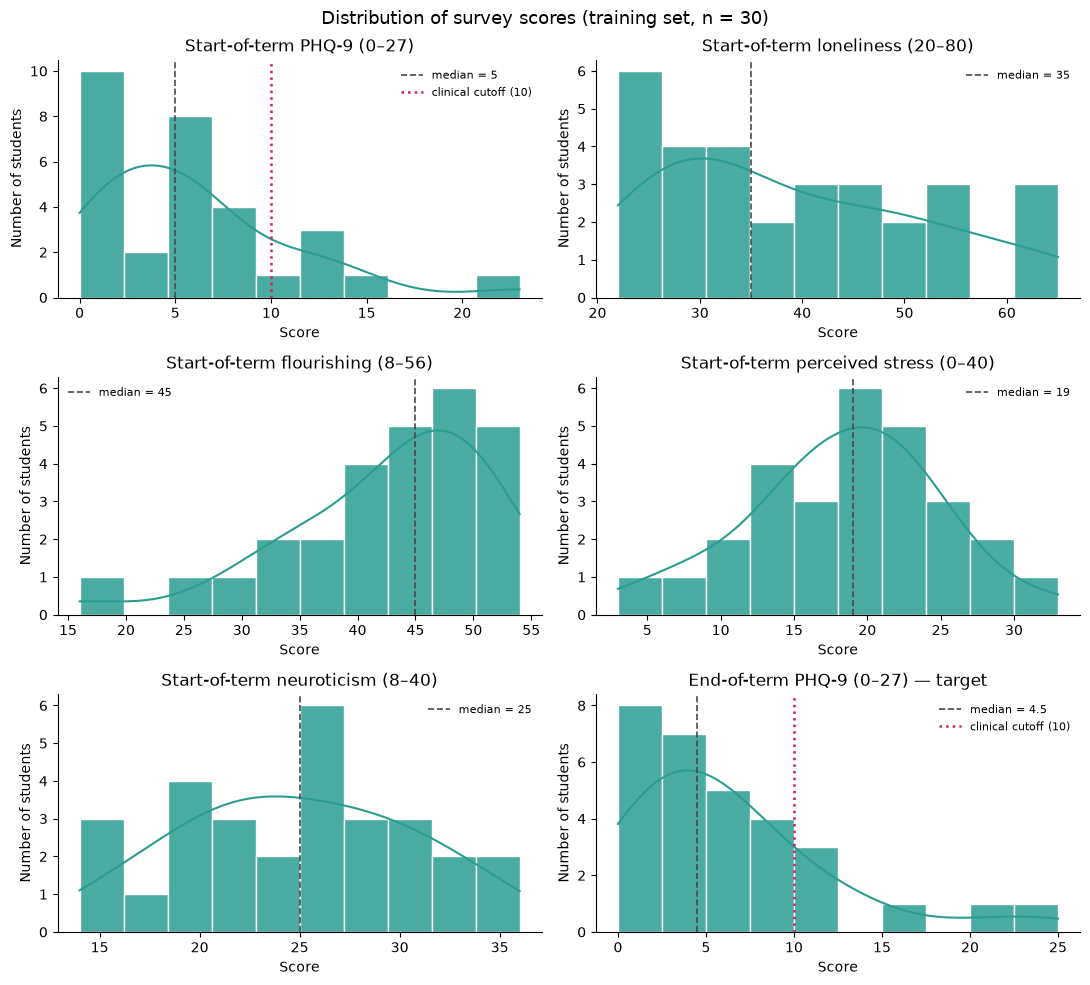

In [49]:
# Distributions of each score (training data)
import matplotlib.pyplot as plt
import seaborn as sns

HIST_COLOR = "#2A9D8F" 

plot_info = {
    "phq9_pre": "Start-of-term PHQ-9 (0–27)",
    "loneliness_pre": "Start-of-term loneliness (20–80)",
    "flourishing_pre": "Start-of-term flourishing (8–56)",
    "stress_pre": "Start-of-term perceived stress (0–40)",
    "neuroticism_pre": "Start-of-term neuroticism (8–40)",
    "phq9_post": "End-of-term PHQ-9 (0–27) — target",
}

fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, (column, label) in zip(axes.flat, plot_info.items()):
    sns.histplot(student_train[column].dropna(), bins=10, kde=True, ax=ax,
                 color=HIST_COLOR, edgecolor="white", alpha=0.85)
    ax.axvline(student_train[column].median(), color="#4A4A4A", linestyle="--", linewidth=1.2,
               label=f"median = {student_train[column].median():g}")
    if column.startswith("phq9"):
        ax.axvline(10, color="#D81B60", linestyle=":", linewidth=1.8, label="clinical cutoff (10)")
    ax.set_title(label)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, frameon=False)

fig.suptitle("Distribution of survey scores (training set, n = 30)", fontsize=13)
plt.tight_layout()
plt.show()

**Takeaway:** Both PHQ-9 distributions are concentrated at low scores with a long right tail —
most students report minimal symptoms, and only a few cross the clinical cutoff of 10. This
imbalance is why the at-risk class is small (6 of 30 training students). Flourishing is
concentrated at high scores with a tail of low-wellbeing students, while loneliness is
more evenly spread. Stress and neuroticism are spread fairly evenly around their midpoints, with no extreme values.

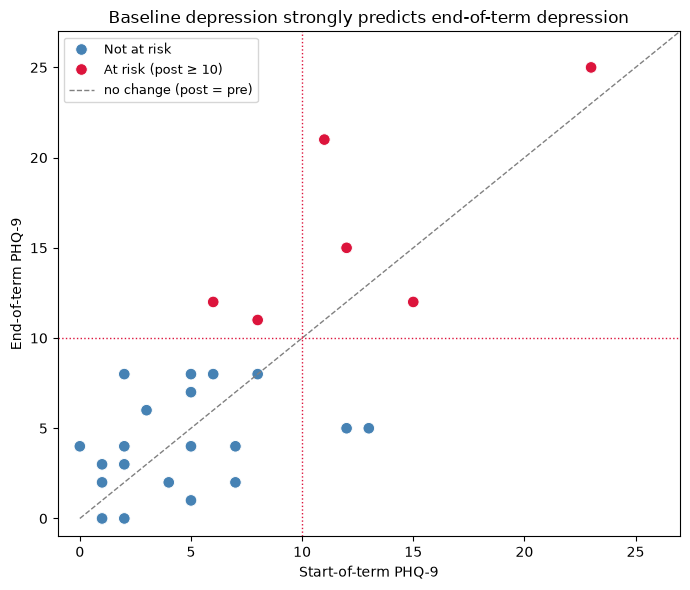

At risk at end,0,1
Flagged at start (pre ≥ 10),,
False,22,2
True,2,4


In [50]:
# Start- vs end-of-term depression, coloured by at-risk status
fig, ax = plt.subplots(figsize=(7, 6))

sns.scatterplot(
    data=student_train, x="phq9_pre", y="phq9_post",
    hue=student_train["at_risk"].map({0: "Not at risk", 1: "At risk (post ≥ 10)"}),
    palette={"Not at risk": "steelblue", "At risk (post ≥ 10)": "crimson"},
    s=70, ax=ax
)
ax.plot([0, 27], [0, 27], color="grey", linestyle="--", linewidth=1, label="no change (post = pre)")
ax.axhline(10, color="crimson", linestyle=":", linewidth=1)
ax.axvline(10, color="crimson", linestyle=":", linewidth=1)

ax.set_xlim(-1, 27)
ax.set_ylim(-1, 27)
ax.set_xlabel("Start-of-term PHQ-9")
ax.set_ylabel("End-of-term PHQ-9")
ax.set_title("Baseline depression strongly predicts end-of-term depression")
ax.legend(title="", fontsize=9)
plt.tight_layout()
plt.show()

# How well would a simple rule ("flag if start-of-term PHQ-9 >= 10") do?
display(pd.crosstab(
    student_train["phq9_pre"] >= 10, student_train["at_risk"],
    rownames=["Flagged at start (pre ≥ 10)"], colnames=["At risk at end"]
))

**Takeaway:** Most students sit close to the "no change" line, so start-of-term depression is a
strong signal for end-of-term depression. But a simple rule (flag every student with PHQ-9 ≥ 10
at the start of term) catches only 4 of the 6 at-risk students in training. It misses two
students (starting at 6 and 8) who **worsened** over the term, and raises two false alarms
(starting at 12–13 but improving to 5). This rule is our **baseline**: a useful model should catch the students whose symptoms get worse, which is where loneliness, flourishing, stress and neuroticism could add value.

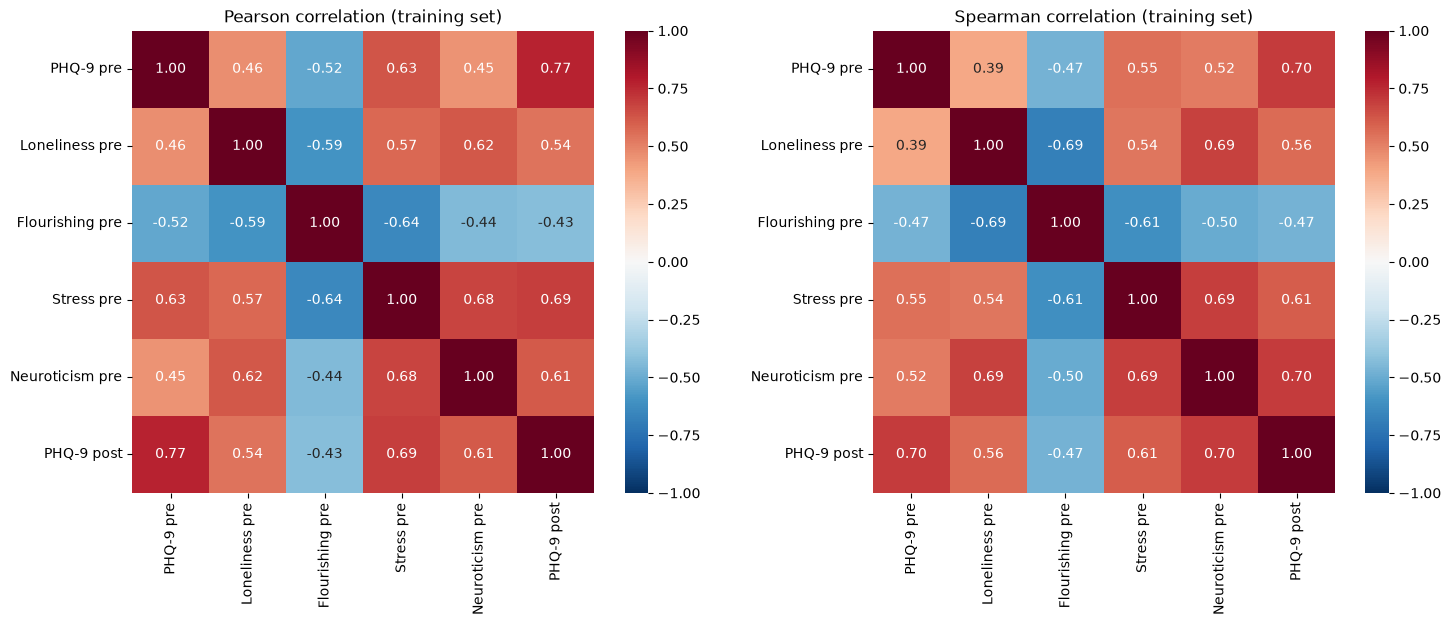

In [51]:
# Correlations between all scores (Pearson and Spearman)
score_columns = ["phq9_pre", "loneliness_pre", "flourishing_pre",
                 "stress_pre", "neuroticism_pre", "phq9_post"]
labels = ["PHQ-9 pre", "Loneliness pre", "Flourishing pre",
          "Stress pre", "Neuroticism pre", "PHQ-9 post"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = student_train[score_columns].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                xticklabels=labels, yticklabels=labels, square=True, ax=ax)
    ax.set_title(f"{method.capitalize()} correlation (training set)")

plt.tight_layout()
plt.show()

**Takeaway:** Start-of-term PHQ-9 remains the strongest predictor of end-of-term PHQ-9
(Pearson r = 0.77), followed by **stress (r = 0.69)** and **neuroticism (r = 0.61)**, both
stronger than loneliness (0.54) and flourishing (−0.43). Spearman correlations, which are less
sensitive to skew and outliers, shift the ranking slightly: neuroticism rises to 0.70, tying
baseline PHQ-9, while stress drops to 0.61. Either way, all four psychological measures are
meaningfully related to end-of-term depression.

However, the predictors are strongly correlated **with each other**: stress correlates 0.63 with
baseline PHQ-9 and 0.68 with neuroticism, and loneliness correlates 0.62 with neuroticism. Much of
the information in the new predictors may already be captured by baseline depression. This
multicollinearity is why we compare feature sets with cross-validation and try regularized
models (Ridge/Lasso), rather than judging predictors by their individual correlations.

In [52]:
# Internal consistency (Cronbach's alpha) of each scale, using training students' item responses
def cronbach_alpha(items):
    """Cronbach's alpha for a DataFrame where each column is one item (rows with missing items dropped)."""
    items = items.dropna()
    k = items.shape[1]
    item_variances = items.var(axis=0, ddof=1).sum()
    total_variance = items.sum(axis=1).var(ddof=1)
    return k / (k - 1) * (1 - item_variances / total_variance), len(items)

train_ids = set(student_train["uid"])

scale_items = {
    "PHQ-9 (9 items)": phq9_clean.loc[
        (phq9_clean["type"] == "pre") & phq9_clean["uid"].isin(train_ids), item_columns
    ].astype(float),
    "UCLA Loneliness (20 items)": loneliness_clean.loc[
        loneliness_clean["uid"].isin(train_ids), loneliness_items
    ].astype(float),
    "Flourishing (8 items)": flourishing_clean.loc[
        flourishing_clean["uid"].isin(train_ids), flourishing_items
    ].astype(float),
        "Perceived Stress (10 items)": stress_clean.loc[
        stress_clean["uid"].isin(train_ids), stress_items
    ].astype(float),
    "Neuroticism (8 items)": bigfive_clean.loc[
        bigfive_clean["uid"].isin(train_ids), neuroticism_items
    ].astype(float),
}

alpha_rows = []
for scale, items in scale_items.items():
    alpha, n_used = cronbach_alpha(items)
    alpha_rows.append({"scale": scale, "cronbach_alpha": round(alpha, 2), "students_used": n_used})

display(pd.DataFrame(alpha_rows).set_index("scale"))

,cronbach_alpha,students_used
scale,,
PHQ-9 (9 items),0.88,30
UCLA Loneliness (20 items),0.95,30
Flourishing (8 items),0.87,27
Perceived Stress (10 items),0.86,28
Neuroticism (8 items),0.82,29


**Takeaway:** All five scales show good internal consistency on the training students'
start-of-term responses (PHQ-9 α = 0.88, UCLA Loneliness α = 0.95, Flourishing α = 0.87,
Perceived Stress α = 0.86, Neuroticism α = 0.82), above the conventional 0.70 threshold. This
supports summing each scale's items into a single total score, as the published scoring methods
do. (Alpha uses only students with complete item responses.)

In [53]:
# Check whether a log transform reduces the skew of the PHQ-9 scores
import numpy as np

skew_check = pd.DataFrame({
    "original_skew": student_train[["phq9_pre", "phq9_post"]].skew(),
    "log1p_skew": np.log1p(student_train[["phq9_pre", "phq9_post"]]).skew(),
}).round(2)

display(skew_check)

,original_skew,log1p_skew
phq9_pre,1.51,-0.19
phq9_post,1.58,-0.48


### Summary of EDA Learnings

**What we learned**
1. **Baseline depression is the dominant signal.** Start-of-term PHQ-9 correlates r = 0.77 with
   end-of-term PHQ-9. Stress (0.69) and neuroticism (0.61) are the next strongest, followed by
   loneliness (0.54) and flourishing (−0.43).
2. **The predictors overlap heavily.** All four psychological measures are correlated with
   baseline PHQ-9 and with each other (|r| = 0.44–0.68), so their unique contribution beyond
   baseline depression may be modest — the central question our nested feature sets (A/B/C) test.
3. **A simple rule is a strong baseline but misses students who get worse.** Flagging students
   with PHQ-9 ≥ 10 at the start catches 4 of 6 at-risk students in training and raises 2 false
   alarms. The 2 missed students started below the cutoff and deteriorated.
4. **PHQ-9 scores are skewed and the at-risk class is rare** (6 of 30 training students), so we
   should use metrics robust to imbalance (recall, ROC-AUC) and cross-validation rather than
   relying on the small test set.
5. **Measurement quality is good.** All five scales have Cronbach's α ≥ 0.82, and all values lie
   within their valid ranges. The extreme scores are real responses, not errors.

**Promising transformations**
- **Log transform of start-of-term PHQ-9:** reduces its skew from 1.5 to −0.2. We treat it as a
  pipeline option and compare with and without it during model selection. (End-of-term PHQ-9 is
  also skewed; transforming the target is a further option for fine-tuning.)
- **Standardization** of all predictors, since they are on different scales (0–27, 20–80, 8–56,
  0–40, 8–40). This is required for regularized models, k-NN and SVMs.
- **Imputation** of the missing flourishing, stress and neuroticism totals (6 training students),
  using the training median inside the pipeline.

**Extra data that would help**
- **A larger sample.** With 38 students (7 at risk), all estimates are noisy; this is a pilot.
- **Mid-term check-ins** (StudentLife's EMA surveys), to catch students who deteriorate mid-term.
- **Passive sensing or wearable data** (sleep, activity, conversation time), available in
  StudentLife and in larger datasets such as GLOBEM, which may capture changes that a one-time
  survey misses.
- **Context variables** such as academic workload, year of study, or major events during the term.

## 4. Prepare the Data

We separate predictors from the two targets. The at-risk label is derived from `phq9_post`, so
neither target is ever used as a predictor (that would be data leakage).

In [54]:
# Separate predictors and targets (training and test sets)
feature_columns = ["phq9_pre", "loneliness_pre", "flourishing_pre", "stress_pre", "neuroticism_pre"]

# Nested feature sets to compare in the modeling section
feature_sets = {
    "A: PHQ-9 only": ["phq9_pre"],
    "B: + loneliness, flourishing": ["phq9_pre", "loneliness_pre", "flourishing_pre"],
    "C: + stress, neuroticism": feature_columns,
}

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train_score = train_data["phq9_post"].copy()   # regression target (0–27)
y_test_score = test_data["phq9_post"].copy()

y_train_risk = train_data["at_risk"].copy()      # classification target (1 = PHQ-9 post >= 10)
y_test_risk = test_data["at_risk"].copy()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (30, 5) | X_test: (8, 5)


All preprocessing is wrapped in a scikit-learn `Pipeline`, so it is learned from training data
only and automatically re-fit inside each cross-validation fold. The function
`make_preprocessor(features)` builds the pipeline for any feature set (A, B or C):

| Feature | Steps | Why |
|---|---|---|
| `phq9_pre` | optional `log1p` → standardize | Right-skewed (skew 1.5 → −0.2 after log); the log is a switch so we can test both versions as a hyperparameter |
| `loneliness_pre` | median imputation → standardize | Roughly symmetric, no missing values (imputation has no effect, but keeps the pipeline uniform) |
| `flourishing_pre` | median imputation → standardize | 3 missing totals in training; the median is robust to the skew and low outlier |
| `stress_pre` | median imputation → standardize | Roughly symmetric, 2 missing totals in training |
| `neuroticism_pre` | median imputation → standardize | Roughly symmetric, 1 missing total in training |

Standardizing puts all scales (0–27, 20–80, 8–56, 0–40, 8–40) on the same footing, which
regularized models, k-NN and SVMs require. We do not remove outliers: the extreme scores are real
students and are exactly the cases a screening tool must detect.

In [55]:
# Reusable, leak-free preprocessing pipeline
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

def make_preprocessor(features, log_phq9=True):
    """
    Build the preprocessing steps for a given list of predictor columns.

    - phq9_pre: optional log1p transform (reduces right skew), then standardize
    - all other predictors: impute missing totals with the training median, then standardize
      (loneliness has no missing values, so imputation simply does nothing there)

    Because these steps live inside a Pipeline, they are re-fit on the training folds only
    during cross-validation, so no information from validation or test students leaks in.
    """
    transformers = []

    if "phq9_pre" in features:
        phq9_steps = [("scale", StandardScaler())]
        if log_phq9:
            phq9_steps.insert(0, ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
        transformers.append(("phq9", Pipeline(phq9_steps), ["phq9_pre"]))

    other_features = [f for f in features if f != "phq9_pre"]
    if other_features:
        transformers.append(("surveys", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), other_features))

    return ColumnTransformer(transformers)

In [56]:
# Sanity check: fit on training data only, then inspect the transformed features
preprocessor = make_preprocessor(feature_columns, log_phq9=True)
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)   # transform only — never fit on test

prepared_check = pd.DataFrame(
    X_train_prepared, columns=preprocessor.get_feature_names_out()
)
print("Missing values after preprocessing:", int(np.isnan(X_train_prepared).sum()))
display(prepared_check.describe().loc[["mean", "std"]].round(2))

imputer = preprocessor.named_transformers_["surveys"].named_steps["impute"]
display(pd.Series(imputer.statistics_, index=feature_columns[1:], name="median used for imputation"))

Missing values after preprocessing: 0


,phq9__phq9_pre,surveys__loneliness_pre,surveys__flourishing_pre,surveys__stress_pre,surveys__neuroticism_pre
mean,0.00,0.00,0.00,-0.00,0.00
std,1.02,1.02,1.02,1.02,1.02


loneliness_pre     35.0
flourishing_pre    45.0
stress_pre         19.0
neuroticism_pre    25.0
Name: median used for imputation, dtype: float64

## 5. Measure and Compare Performance

### Model Selection and Cross-Validation

Import the necessary libraries

In [57]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR, SVC

We are using 3-fold stratified cross-validation to evaluate our models. Our training set only contains 6 at-risk students, so we are stratifying the folds to include both at-risk and not-at-risk students in each one. This helps us compare model performance more consistently.

In [58]:
cv = list(StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
).split(X_train, y_train_risk))

We are selecting models from different algorithm families to compare their performance on both regression and classification tasks. We are also including dummy models as baselines to check whether the other models perform better than simple predictions.

In [59]:
regression_models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "SVR": SVR()
}

classification_models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),
    "SVC": SVC(class_weight="balanced")
}

### Regression Model Comparison

We are comparing the regression models to see how accurately they predict end-of-term PHQ-9 scores. We are using RMSE, MAE, and R² to evaluate their performance across the three feature sets. We are also calculating the mean and standard deviation across the cross-validation folds to compare how consistently each model performs.

In [60]:
regression_results = []

for feature_set, columns in feature_sets.items():
    for name, model in regression_models.items():

        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(columns)),
            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train[columns],
            y_train_score,
            cv=cv,
            scoring={
                "rmse": "neg_root_mean_squared_error",
                "mae": "neg_mean_absolute_error",
                "r2": "r2"
            }
        )

        regression_results.append({
            "Feature Set": feature_set,
            "Model": name,
            "Mean RMSE": -scores["test_rmse"].mean(),
            "Std RMSE": scores["test_rmse"].std(),
            "Mean MAE": -scores["test_mae"].mean(),
            "Std MAE": scores["test_mae"].std(),
            "Mean R2": scores["test_r2"].mean(),
            "Std R2": scores["test_r2"].std()
        })

regression_results = pd.DataFrame(regression_results)

In [61]:
display(
    regression_results.sort_values(
        "Mean RMSE"
    ).round(3)
)

,Feature Set,Model,Mean RMSE,Std RMSE,Mean MAE,Std MAE,Mean R2,Std R2
13,"C: + stress, neuroticism",Random Forest,4.348,1.677,3.570,1.487,0.434,0.181
8,"B: + loneliness, flourishing",Random Forest,4.405,0.691,3.593,0.680,0.341,0.222
2,A: PHQ-9 only,Ridge,4.735,0.305,3.715,0.220,0.226,0.240
1,A: PHQ-9 only,Linear Regression,4.743,0.232,3.715,0.176,0.213,0.271
12,"C: + stress, neuroticism",Ridge,4.877,1.165,3.946,1.074,0.128,0.494
11,"C: + stress, neuroticism",Linear Regression,5.019,1.175,4.049,1.084,0.064,0.530
3,A: PHQ-9 only,Random Forest,5.112,0.544,4.289,0.307,0.114,0.255
7,"B: + loneliness, flourishing",Ridge,5.113,1.393,4.029,1.234,-0.017,0.646
6,"B: + loneliness, flourishing",Linear Regression,5.204,1.460,4.109,1.272,-0.075,0.691
4,A: PHQ-9 only,SVR,5.539,1.078,4.037,0.695,0.022,0.115


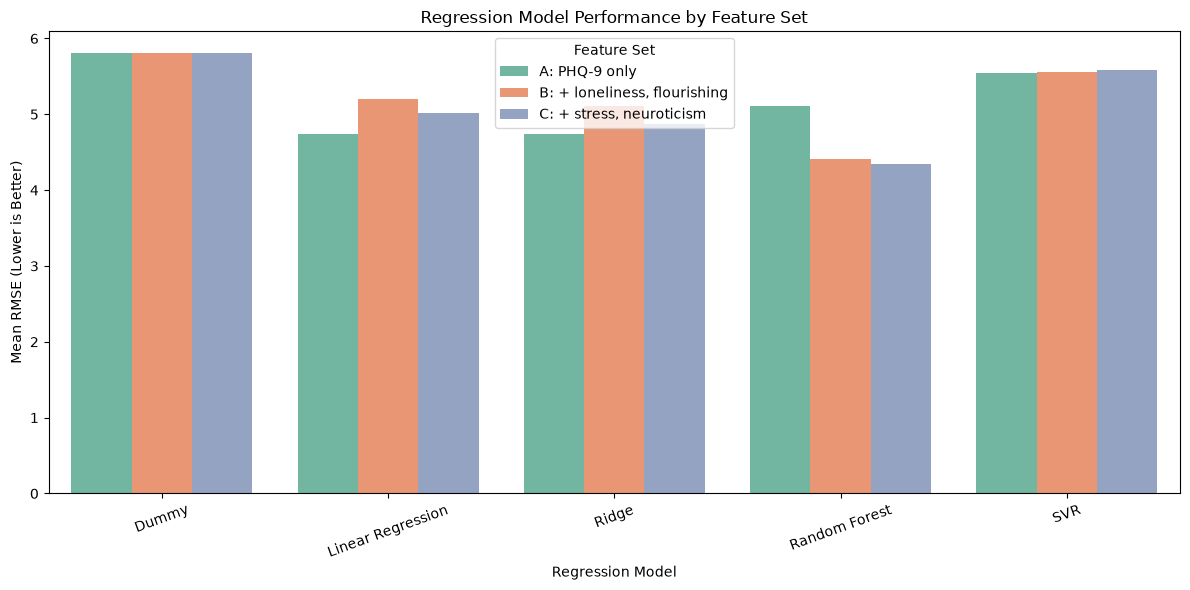

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=regression_results,
    x="Model",
    y="Mean RMSE",
    hue="Feature Set",
    palette="Set2"
)

plt.title("Regression Model Performance by Feature Set")
plt.xlabel("Regression Model")
plt.ylabel("Mean RMSE (Lower is Better)")
plt.xticks(rotation=20)
plt.legend(title="Feature Set")
plt.tight_layout()
plt.show()

We are identifying the five model and feature set combinations with the lowest mean RMSE to highlight the strongest regression results.

In [63]:
# Show the five combinations with the lowest RMSE
top_regression = regression_results.nsmallest(
    5, "Mean RMSE"
)

display(top_regression.round(3))

,Feature Set,Model,Mean RMSE,Std RMSE,Mean MAE,Std MAE,Mean R2,Std R2
13,"C: + stress, neuroticism",Random Forest,4.348,1.677,3.570,1.487,0.434,0.181
8,"B: + loneliness, flourishing",Random Forest,4.405,0.691,3.593,0.680,0.341,0.222
2,A: PHQ-9 only,Ridge,4.735,0.305,3.715,0.220,0.226,0.240
1,A: PHQ-9 only,Linear Regression,4.743,0.232,3.715,0.176,0.213,0.271
12,"C: + stress, neuroticism",Ridge,4.877,1.165,3.946,1.074,0.128,0.494


#### Regression Results and Interpretation

Random Forest with Feature Set C performs the best overall, achieving the lowest RMSE of 4.348 and highest R² of 0.434. Feature Set B also performs well with Random Forest, with a slightly higher RMSE of 4.405 but a lower standard deviation, suggesting more consistent performance. Ridge Regression with Feature Set A performs relatively well using only baseline PHQ-9 scores. All models outperform the dummy baseline in RMSE, while SVR generally performs the worst. These results suggest that additional survey features can improve predictions, although the improvement varies depending on the model.

### Classification Model Comparison

We are comparing the classification models to see how accurately they identify students who are at risk of depression at the end of the term (PHQ-9 ≥ 10). We are using recall, precision, F1-score, and balanced accuracy to evaluate performance across the three feature sets. We are also calculating the mean and standard deviation across the cross-validation folds to compare how consistently each model performs.

In [64]:
from sklearn.metrics import make_scorer, precision_score, f1_score

classification_results = []

for feature_set, columns in feature_sets.items():
    for name, model in classification_models.items():

        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(columns)),
            ("model", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train[columns],
            y_train_risk,
            cv=cv,
            scoring={
                "recall": "recall",
                "precision": make_scorer(precision_score, zero_division=0),
                "f1": make_scorer(f1_score, zero_division=0),
                "balanced_accuracy": "balanced_accuracy"
            }
        )

        classification_results.append({
            "Feature Set": feature_set,
            "Model": name,
            "Mean Recall": scores["test_recall"].mean(),
            "Std Recall": scores["test_recall"].std(),
            "Mean Precision": scores["test_precision"].mean(),
            "Std Precision": scores["test_precision"].std(),
            "Mean F1": scores["test_f1"].mean(),
            "Std F1": scores["test_f1"].std(),
            "Mean Balanced Accuracy": scores[
                "test_balanced_accuracy"
            ].mean(),
            "Std Balanced Accuracy": scores[
                "test_balanced_accuracy"
            ].std()
        })

classification_results = pd.DataFrame(classification_results)

In [65]:
display(
    classification_results.sort_values(
        ["Mean Recall", "Mean F1"],
        ascending=[False, False]
    ).round(3)
)

,Feature Set,Model,Mean Recall,Std Recall,Mean Precision,Std Precision,Mean F1,Std F1,Mean Balanced Accuracy,Std Balanced Accuracy
11,"C: + stress, neuroticism",SVC,1.000,0.000,0.778,0.157,0.867,0.094,0.958,0.029
9,"C: + stress, neuroticism",Logistic Regression,1.000,0.000,0.611,0.079,0.756,0.063,0.917,0.029
10,"C: + stress, neuroticism",Random Forest,0.833,0.236,0.778,0.157,0.756,0.063,0.875,0.088
1,A: PHQ-9 only,Logistic Regression,0.833,0.236,0.611,0.079,0.700,0.141,0.854,0.118
7,"B: + loneliness, flourishing",SVC,0.833,0.236,0.689,0.245,0.679,0.094,0.833,0.078
6,"B: + loneliness, flourishing",Random Forest,0.667,0.236,0.556,0.314,0.600,0.283,0.750,0.177
5,"B: + loneliness, flourishing",Logistic Regression,0.667,0.236,0.400,0.196,0.495,0.220,0.688,0.184
3,A: PHQ-9 only,SVC,0.500,0.000,0.417,0.118,0.444,0.079,0.646,0.059
2,A: PHQ-9 only,Random Forest,0.500,0.408,0.333,0.272,0.400,0.327,0.625,0.255
0,A: PHQ-9 only,Dummy,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000


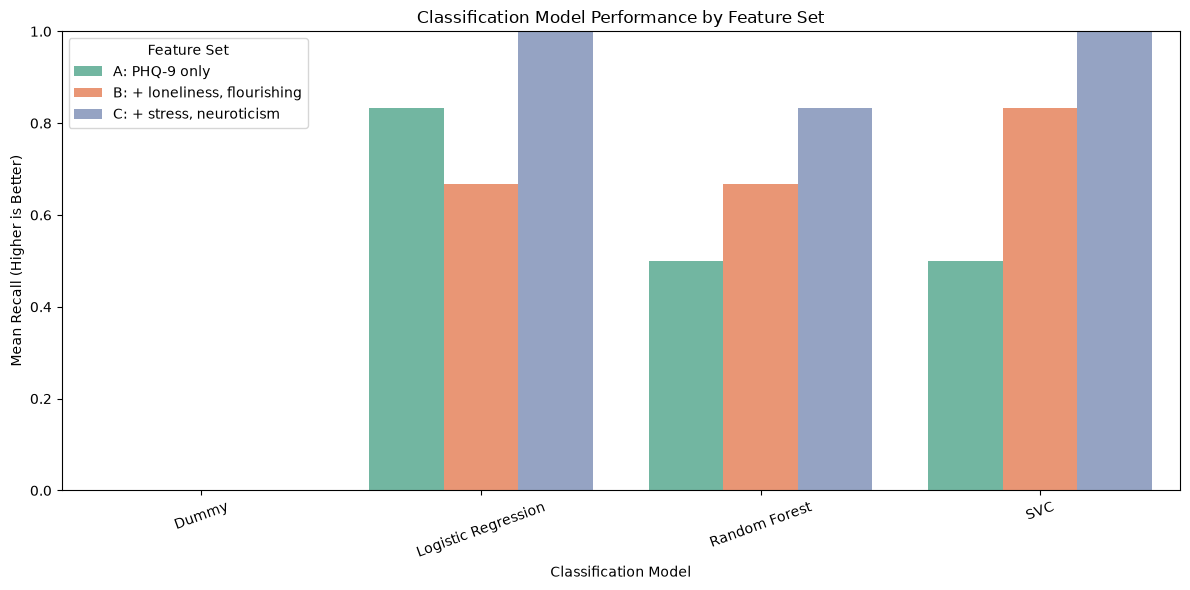

In [66]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_results,
    x="Model",
    y="Mean Recall",
    hue="Feature Set",
    palette="Set2"
)

plt.title("Classification Model Performance by Feature Set")
plt.xlabel("Classification Model")
plt.ylabel("Mean Recall (Higher is Better)")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Feature Set")
plt.tight_layout()
plt.show()

We are also comparing our classification models against a simple screening rule that flags students with a start-of-term PHQ-9 score of 10 or higher. We are evaluating this rule using the same cross-validation folds to see whether our models can identify more at-risk students.

In [67]:
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

screening_results = []

for train_idx, val_idx in cv:

    y_true = y_train_risk.iloc[val_idx]

    # Flag students with baseline PHQ-9 >= 10
    y_pred = (
        X_train.iloc[val_idx]["phq9_pre"] >= 10
    ).astype(int)

    screening_results.append({
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    })

screening_results = pd.DataFrame(screening_results)

screening_summary = pd.DataFrame({
    "Mean": screening_results.mean(),
    "Std": screening_results.std(ddof=0)
})

display(screening_summary.round(3))

,Mean,Std
Recall,0.667,0.236
Precision,0.722,0.208
F1,0.656,0.123
Balanced Accuracy,0.792,0.106


We are identifying the five model and feature set combinations with the highest recall, using F1-score to break ties. We are prioritizing recall because identifying students who are at risk is our main classification objective.

In [68]:
top_classification = classification_results.sort_values(
    ["Mean Recall", "Mean F1"],
    ascending=[False, False]
).head(5)

display(top_classification.round(3))

,Feature Set,Model,Mean Recall,Std Recall,Mean Precision,Std Precision,Mean F1,Std F1,Mean Balanced Accuracy,Std Balanced Accuracy
11,"C: + stress, neuroticism",SVC,1.000,0.000,0.778,0.157,0.867,0.094,0.958,0.029
9,"C: + stress, neuroticism",Logistic Regression,1.000,0.000,0.611,0.079,0.756,0.063,0.917,0.029
10,"C: + stress, neuroticism",Random Forest,0.833,0.236,0.778,0.157,0.756,0.063,0.875,0.088
1,A: PHQ-9 only,Logistic Regression,0.833,0.236,0.611,0.079,0.700,0.141,0.854,0.118
7,"B: + loneliness, flourishing",SVC,0.833,0.236,0.689,0.245,0.679,0.094,0.833,0.078


#### Classification Results and Interpretation

SVC with Feature Set C performs the best overall, achieving a recall of 1.000, precision of 0.778, and F1-score of 0.867. Logistic Regression with Feature Set C also achieves perfect recall, but has lower precision. Both models outperform the existing screening rule, which only achieves a recall of 0.667. Feature Set C generally performs better for the strongest classification models, suggesting that adding stress and neuroticism helps identify at-risk students. However, our dataset is small, so these results may not generalize to a larger student population. Since each validation fold only contains 2 at-risk students, small differences in predictions can have a large impact on recall. We are treating these results as preliminary because of the limited sample size.

### Feature Importance Analysis

In [69]:
# Imports for feature importance (permutation method, which works for any model type) and out-of-fold predictions for error analysis
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_predict

In [70]:
# Refitting winning models/feature-set combinations (Random Forest for regression and SVC for classification, both with Feature Set C) on the full training so they can be inspected directly
best_feature_set = "C: + stress, neuroticism"
cols_C = feature_sets[best_feature_set]

best_reg_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_C)),
    ("model", RandomForestRegressor(n_estimators=100, random_state=42))
]).fit(X_train[cols_C], y_train_score)

best_clf_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_C)),
    ("model", SVC(class_weight="balanced"))
]).fit(X_train[cols_C], y_train_risk)

Feature importance using the permutation method:
For each feature, its values are shuffled and measured based on how much the model's score drops; in this case, a larger drop suggests that the model relied more on that specific feature. This method was chosen over .feature_importances_ or .coef_ because it works consistently between both types, and SVC with the default kernel has no coefficients to read directly

In [71]:
reg_importance = permutation_importance(
    best_reg_pipeline, X_train[cols_C], y_train_score,
    scoring="neg_root_mean_squared_error", n_repeats=30, random_state=42
)
clf_importance = permutation_importance(
    best_clf_pipeline, X_train[cols_C], y_train_risk,
    scoring="recall", n_repeats=30, random_state=42
)

print("Most important predictors for the regression model (Random Forest):")
display(pd.Series(reg_importance.importances_mean, index=cols_C).sort_values(ascending=False))

print("Most important predictors for the classification model (SVC):")
display(pd.Series(clf_importance.importances_mean, index=cols_C).sort_values(ascending=False))

Most important predictors for the regression model (Random Forest):


neuroticism_pre    2.091366
stress_pre         1.790359
phq9_pre           0.752300
loneliness_pre     0.715798
flourishing_pre    0.605826
dtype: float64

Most important predictors for the classification model (SVC):


neuroticism_pre    0.411111
phq9_pre           0.272222
stress_pre         0.183333
flourishing_pre    0.061111
loneliness_pre     0.000000
dtype: float64


For both the regression and classification models, `neuroticism_pre` ranks as the most important predictor, even over `phq9_pre`, despite baseline PHQ-9 having the strongest raw correlation with the target during the exploratory data analysis phase. This likely reflects the multicollinearity noted earlier since with several correlated predictors in the model, importance can shift toward whichever variable the model finds marginally more useful, which is sensitive to noise at this sample size. `loneliness_pre` is more or less the least important predictor to either model (0.000 importance for classification), making it the clearest predictor to drop in feature selection. Since Random Forest here has no depth limit, it can fit noise with only 30 training rows, so the importance estimates should be treated as suggestive rather than definitive.


### Regression Error Analysis

In [72]:
# Out-of-fold predictions using the same cross-validation folds from the model comparison above, so these errors reflect genuine held-out performance instead of the model simply recalling the training data
reg_preds = cross_val_predict(best_reg_pipeline, X_train[cols_C], y_train_score, cv=cv)

error_table = pd.DataFrame({
    "uid": train_data["uid"],
    "phq9_pre": X_train["phq9_pre"],
    "actual": y_train_score,
    "predicted": reg_preds.round(1),
    "residual": (y_train_score - reg_preds).round(1)
}).sort_values("residual", key=abs, ascending=False)

# Students with the largest residuals show where the regression model struggles most
display(error_table.head(8))

,uid,phq9_pre,actual,predicted,residual
26,u42,1.0,0.0,12.5,-12.5
0,u00,2.0,3.0,13.4,-10.4
16,u23,11.0,21.0,11.4,9.6
22,u33,23.0,25.0,17.7,7.3
13,u18,15.0,12.0,18.4,-6.4
32,u51,1.0,0.0,5.5,-5.5
31,u49,2.0,8.0,3.6,4.4
4,u04,6.0,8.0,12.2,-4.2


Two error types are observed from the regression analysis. One notable error is that the model produced false alarms for low-baseline students. For instance, u42, u00, and u51 all started with phq9_pre of 1–2 (essentially no symptoms) and stayed low (actual 0–3); however, the model overestimated and predicted 5.5–13.4. Since neuroticism/stress ranked as the top predictors, the model may be reading high trait-neuroticism or stress as a depression signal even when the student's actual symptoms never followed. Another error is that the model missed deteriorators. For example, u23 (pre=11, actual=21) and u49 (pre=2, actual=8) both got noticeably worse over the term, but the model did not move its prediction from their baseline, which was already flagged during the exploratory data analysis.

### Classification Error Analysis

In [73]:
# Same out-of-fold approach for the classifier to see which students get mislabeled rather than only the aggregate recall/precision
clf_preds = cross_val_predict(best_clf_pipeline, X_train[cols_C], y_train_risk, cv=cv)

misclassified = pd.DataFrame({
    "uid": train_data["uid"],
    "actual_risk": y_train_risk,
    "predicted_risk": clf_preds
}).query("actual_risk != predicted_risk")

# Listing students that the model misclassified since false negatives (a missed at-risk student) are the more serious error type for a screening tool 
display(misclassified)

,uid,actual_risk,predicted_risk
4,u04,0,1
2,u02,0,1


Fortunately, the classification error were both false positives, not false negatives. For example, u04 and u02 were predicted at-risk but weren’t; u02 (pre=13, actual=5) matches a student the initial exploratory data analysis identified as a “started high, improved” false alarm, so the SVC is reproducing the same miss as the simple screening rule it is meant to outperform. 

**Human Error Prevention**
- To avoid these errors, a human advisor could have mid-term check-ins or academic performance data to catch what the model missed. 
- Since the students only filled out a start-of-term survey, the data from the mid-term check-ins can capture the false alarms since a high-stress student at the beginning of the semester would now be recorded to be coping okay by mid-term. 
- For students whose symptoms worsen by mid-term, a mid-term signal would catch a decline that the model would have not predict from the single baseline snapshot. 


### Feature Selection (Re-evaluating after dropping "loneliness_pre")

Permutation importance showed `loneliness_pre` contributes the least to either model (0.000 importance for classification). We test a trimmed Feature Set D that drops it to see whether removing a insignificant predictor changes performance since a simpler model with the same performance preferrable, easier to justify, and less prone to overfitting on this small sample.

In [74]:
# Feature Set D: same as C, but drop loneliness_pre (near-zero importance in both models)
feature_sets["D: C minus loneliness"] = ["phq9_pre", "flourishing_pre", "stress_pre", "neuroticism_pre"]

In [75]:
# Re-run the same comparison loop as before, but only for the new feature set and append results to the existing tables so D can be compared directly
for name, model in regression_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(feature_sets["D: C minus loneliness"])),
        ("model", model)
    ])
    scores = cross_validate(
        pipeline, X_train[feature_sets["D: C minus loneliness"]], y_train_score,
        cv=cv, scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
    )
    regression_results = pd.concat([regression_results, pd.DataFrame([{
        "Feature Set": "D: C minus loneliness", "Model": name,
        "Mean RMSE": -scores["test_rmse"].mean(), "Std RMSE": scores["test_rmse"].std(),
        "Mean MAE": -scores["test_mae"].mean(), "Std MAE": scores["test_mae"].std(),
        "Mean R2": scores["test_r2"].mean(), "Std R2": scores["test_r2"].std()
    }])], ignore_index=True)

for name, model in classification_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(feature_sets["D: C minus loneliness"])),
        ("model", model)
    ])
    scores = cross_validate(
        pipeline, X_train[feature_sets["D: C minus loneliness"]], y_train_risk,
        cv=cv, scoring={"recall": "recall", "precision": make_scorer(precision_score, zero_division=0),
                         "f1": make_scorer(f1_score, zero_division=0), "balanced_accuracy": "balanced_accuracy"}
    )
    classification_results = pd.concat([classification_results, pd.DataFrame([{
        "Feature Set": "D: C minus loneliness", "Model": name,
        "Mean Recall": scores["test_recall"].mean(), "Std Recall": scores["test_recall"].std(),
        "Mean Precision": scores["test_precision"].mean(), "Std Precision": scores["test_precision"].std(),
        "Mean F1": scores["test_f1"].mean(), "Std F1": scores["test_f1"].std(),
        "Mean Balanced Accuracy": scores["test_balanced_accuracy"].mean(), "Std Balanced Accuracy": scores["test_balanced_accuracy"].std()
    }])], ignore_index=True)

In [76]:
# Compare Feature Set C (full) against D (trimmed) for the two winning models
display(regression_results.query("Model == 'Random Forest'").sort_values("Mean RMSE").round(3))
display(classification_results.query("Model == 'SVC'").sort_values(["Mean Recall", "Mean F1"], ascending=[False, False]).round(3))

,Feature Set,Model,Mean RMSE,Std RMSE,Mean MAE,Std MAE,Mean R2,Std R2
13,"C: + stress, neuroticism",Random Forest,4.348,1.677,3.570,1.487,0.434,0.181
18,D: C minus loneliness,Random Forest,4.396,1.486,3.621,1.363,0.412,0.157
8,"B: + loneliness, flourishing",Random Forest,4.405,0.691,3.593,0.680,0.341,0.222
3,A: PHQ-9 only,Random Forest,5.112,0.544,4.289,0.307,0.114,0.255


,Feature Set,Model,Mean Recall,Std Recall,Mean Precision,Std Precision,Mean F1,Std F1,Mean Balanced Accuracy,Std Balanced Accuracy
11,"C: + stress, neuroticism",SVC,1.000,0.000,0.778,0.157,0.867,0.094,0.958,0.029
15,D: C minus loneliness,SVC,0.833,0.236,0.722,0.208,0.767,0.205,0.875,0.135
7,"B: + loneliness, flourishing",SVC,0.833,0.236,0.689,0.245,0.679,0.094,0.833,0.078
3,A: PHQ-9 only,SVC,0.500,0.000,0.417,0.118,0.444,0.079,0.646,0.059


Dropping `loneliness_pre` (Feature Set D) essentially has no change in regression performance (RMSE 4.396 vs. 4.348 for C) and even slightly lowers its variance across folds. However, dropping this feature significantly affects classification, as recall drops from 1.000 to 0.833 and F1 from 0.867 to 0.767. With this in mind, permutation importance near zero does not guarantee a feature is safe to drop. Using the permutation method measures the effect of scrambling a feature within the existing model, not the effect of refitting without it, and SVC's non-linear kernel may use `loneliness_pre` in combination with other predictors. We keep the full Feature Set C for both models based on this result.

### Shortlist Models
Regression: 
- Random Forest + Feature Set C: Best RMSE (4.348) and R² (0.434); non-linear, captures interactions between stress/neuroticism/phq9_pre.
- Random Forest + Feature Set B: Nearly identical RMSE (4.405) but much lower variance (std 0.691 vs 1.677); a more consistent alternative and is worth keeping since Feature Set C’s higher variance may be by chance in the small sample
- Ridge + Feature Set A: Performed relatively well using only baseline PHQ-9; it's linear/regularized (very different error structure from the tree-based models) and far more interpretable

Classification: 
- SVC + Feature Set C: Best model overall with a recall of 1.000 and F1-score of 0.867
- Logistic Regression + Feature Set C: Also perfect recall, lower precision; linear and interpretable (you can read off coefficients) unlike SVC’s non-linear kernel

## 6. Fine-Tuning the System

Each shortlisted model will use `RandomizedSearchCV`, since several hyperparameters have many possible values, to search both model hyperparameters and the imputation strategy for missing survey scores (median vs mean). All searches use the same 3-fold stratified cross-validation.

#### Regression: Random Forest + Feature Set C

In [77]:
from sklearn.model_selection import RandomizedSearchCV

cols_C = feature_sets["C: + stress, neuroticism"]

rf_reg_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_C)),
    ("model", RandomForestRegressor(random_state=42))
])

rf_reg_param_dist = {
    "preprocessor__surveys__impute__strategy": ["median", "mean"],
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4, None],          # None = unrestricted, included for comparison
    "model__min_samples_leaf": [1, 2, 3, 5],
}

rf_reg_search = RandomizedSearchCV(
    rf_reg_pipeline, rf_reg_param_dist, n_iter=20, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42
)
rf_reg_search.fit(X_train[cols_C], y_train_score)

print("Best params:", rf_reg_search.best_params_)
print("Best CV RMSE:", -rf_reg_search.best_score_)

Best params: {'preprocessor__surveys__impute__strategy': 'mean', 'model__n_estimators': 100, 'model__min_samples_leaf': 3, 'model__max_depth': None}
Best CV RMSE: 3.993215297207641


#### Regression: Random Forest + Feature Set B

In [78]:
cols_B = feature_sets["B: + loneliness, flourishing"]

rf_b_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_B)),
    ("model", RandomForestRegressor(random_state=42))
])

rf_b_param_dist = {
    "preprocessor__surveys__impute__strategy": ["median", "mean"],
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4, None],
    "model__min_samples_leaf": [1, 2, 3, 5],
}

rf_b_search = RandomizedSearchCV(
    rf_b_pipeline, rf_b_param_dist, n_iter=20, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42
)
rf_b_search.fit(X_train[cols_B], y_train_score)

print("Best params:", rf_b_search.best_params_)
print("Best CV RMSE:", -rf_b_search.best_score_)

Best params: {'preprocessor__surveys__impute__strategy': 'median', 'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_depth': 3}
Best CV RMSE: 4.296814801972574


#### Regression: Ridge + Feature Set A

In [79]:
cols_A = feature_sets["A: PHQ-9 only"]

ridge_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_A)),
    ("model", Ridge())
])

ridge_param_dist = {
    "model__alpha": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
}

ridge_search = RandomizedSearchCV(
    ridge_pipeline, ridge_param_dist, n_iter=7, cv=cv,
    scoring="neg_root_mean_squared_error", random_state=42
)
ridge_search.fit(X_train[cols_A], y_train_score)

print("Best params:", ridge_search.best_params_)
print("Best CV RMSE:", -ridge_search.best_score_)

Best params: {'model__alpha': 3.0}
Best CV RMSE: 4.734935638059269


#### Classification: SVC + Feature Set C

In [80]:
from sklearn.metrics import make_scorer, f1_score

svc_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_C)),
    ("model", SVC(class_weight="balanced"))
])

svc_param_dist = {
    "preprocessor__surveys__impute__strategy": ["median", "mean"],
    "model__C": [0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
    "model__kernel": ["rbf", "linear"],
    "model__gamma": ["scale", "auto"],
}

svc_search = RandomizedSearchCV(
    svc_pipeline, svc_param_dist, n_iter=20, cv=cv,
    scoring="recall", random_state=42
)
svc_search.fit(X_train[cols_C], y_train_risk)

print("Best params:", svc_search.best_params_)
print("Best CV recall:", svc_search.best_score_)

Best params: {'preprocessor__surveys__impute__strategy': 'mean', 'model__kernel': 'linear', 'model__gamma': 'scale', 'model__C': 3.0}
Best CV recall: 1.0


In [81]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import precision_score

best_svc_pipeline = svc_search.best_estimator_

check_scores = cross_validate(
    best_svc_pipeline, X_train[cols_C], y_train_risk, cv=cv,
    scoring={"recall": "recall", "precision": make_scorer(precision_score, zero_division=0), "f1": "f1"}
)

print("Recall:", check_scores["test_recall"].mean())
print("Precision:", check_scores["test_precision"].mean())
print("F1:", check_scores["test_f1"].mean())

Recall: 1.0
Precision: 0.7222222222222222
F1: 0.8222222222222223


#### Classification: Logistic Regression + Feature Set C

In [82]:
logreg_pipeline = Pipeline([
    ("preprocessor", make_preprocessor(cols_C)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

logreg_param_dist = {
    "preprocessor__surveys__impute__strategy": ["median", "mean"],
    "model__C": [0.01, 0.1, 0.3, 1.0, 3.0, 10.0],
    "model__penalty": ["l2"],
}

logreg_search = RandomizedSearchCV(
    logreg_pipeline, logreg_param_dist, n_iter=12, cv=cv,
    scoring="recall", random_state=42
)
logreg_search.fit(X_train[cols_C], y_train_risk)

print("Best params:", logreg_search.best_params_)
print("Best CV recall:", logreg_search.best_score_)

c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\U

Best params: {'preprocessor__surveys__impute__strategy': 'median', 'model__penalty': 'l2', 'model__C': 0.1}
Best CV recall: 1.0


c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [83]:
best_logreg_pipeline = logreg_search.best_estimator_

check_scores = cross_validate(
    best_logreg_pipeline, X_train[cols_C], y_train_risk, cv=cv,
    scoring={"recall": "recall", "precision": make_scorer(precision_score, zero_division=0), "f1": "f1"}
)

print("Recall:", check_scores["test_recall"].mean())
print("Precision:", check_scores["test_precision"].mean())
print("F1:", check_scores["test_f1"].mean())

Recall: 1.0
Precision: 0.611111111111111
F1: 0.7555555555555555


c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Cathy\Desktop\student-burnout-analysis\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\U

### Tuned Model Comparison

| Task | Model | Metric | Result |
|---|---|---|---|
| Regression | Random Forest + Feature Set C | RMSE | **3.993** (best) |
| Regression | Random Forest + Feature Set B | RMSE | 4.297 |
| Regression | Ridge + Feature Set A | RMSE | 4.735 |
| Classification | SVC + Feature Set C | Recall / Precision / F1 | 1.000 / 0.722 / 0.822 (best) |
| Classification | Logistic Regression + Feature Set C | Recall / Precision / F1 | 1.000 / 0.611 / 0.756 |

Tuning improved every regression model's RMSE, with Random Forest + Feature Set C remaining the strongest after tuning (3.993). For classification, both SVC and Logistic Regression reached perfect recall after tuning, but SVC held a clear precision advantage (0.722 vs. 0.611), making it the stronger standalone classifier. We carry both classifiers forward into ensembling since their different precision/recall tradeoffs mean they may make different mistakes on different students. 